# 1. Data Acquisition
Duyệt danh sách bệnh nhân trên PhysioNet, chọn cohort, đọc numerics record.

## 1.0 Import & cấu hình

In [1]:
import wfdb
import pandas as pd
import numpy as np
import requests
import random

DB_NAME = "mimic3wdb-matched"
DB_VERSION = "1.0"
RECORDS_URL = f"https://physionet.org/files/{DB_NAME}/{DB_VERSION}/RECORDS-numerics"

random.seed(42)  

## 1.1 - 1.2 Sàng lọc ứng viên
Đã chuyển sang chạy độc lập qua `screening.py` (ngoài notebook) do thời gian chạy dài (~2-3 tiếng, gọi mạng liên tục tới PhysioNet) — chạy trong kernel Jupyter dễ bị crash giữa chừng. Log đầy đủ xem tại `screening_log.txt`. Ở đây chỉ đọc lại kết quả đã lưu.

In [2]:
screening_df = pd.read_parquet("screening_checkpoint.parquet")
print(f"Đã đọc {len(screening_df)} ứng viên hợp lệ từ checkpoint")
screening_df.head()

Đã đọc 1600 ứng viên hợp lệ từ checkpoint


,patient_id,record_path,spo2_min_proxy,spo2_mean_proxy,pulse_mean_proxy,dropout_ratio_spo2,has_resp_signal,n_windows_scanned
0,p005909,p00/p005909/p005909-2183-03-25-08-08n,87.0,90.500000,63.714425,0.010000,True,2
1,p015465,p01/p015465/p015465-2129-12-08-12-34n,96.2,96.200000,127.484615,0.133333,True,1
2,p014714,p01/p014714/p014714-2151-01-12-19-51n,90.0,90.666667,105.331667,0.000000,True,3
3,p022384,p02/p022384/p022384-2185-03-22-20-11n,73.0,85.000000,76.131469,0.103889,True,2
4,p023603,p02/p023603/p023603-2114-07-17-00-32n,95.3,96.300000,59.538772,0.255556,True,3


In [3]:
MAX_DROPOUT_RATIO = 0.20
FINAL_COHORT_SIZE = 350

quality_filtered_df = screening_df[screening_df["dropout_ratio_spo2"] <= MAX_DROPOUT_RATIO].copy()
print(f"Còn lại sau lọc dropout: {len(quality_filtered_df)} / {len(screening_df)}")

# Chia bucket theo mức độ nặng
bins = [0, 90, 94, 97, 101]
labels = ["<90", "90-94", "94-97", ">97"]
quality_filtered_df["severity_bucket"] = pd.cut(
    quality_filtered_df["spo2_min_proxy"], bins=bins, labels=labels, right=False
)
print(quality_filtered_df["severity_bucket"].value_counts())

# Tỷ lệ mong muốn mỗi bucket + thứ tự ưu tiên bù (liền kề mức độ nặng trước)
bucket_quota = {"<90": 0.25, "90-94": 0.30, "94-97": 0.30, ">97": 0.15}
fallback_order = {
    "<90": ["90-94", "94-97", ">97"],
    "90-94": ["<90", "94-97", ">97"],
    "94-97": ["90-94", ">97", "<90"],
    ">97": ["94-97", "90-94", "<90"],
}

target_n = {b: round(FINAL_COHORT_SIZE * frac) for b, frac in bucket_quota.items()}
pools = {
    b: quality_filtered_df[quality_filtered_df["severity_bucket"] == b].sample(frac=1, random_state=42)
    for b in labels
}

sampled_parts = []
deficit = 0
for bucket in labels:
    n_take = min(len(pools[bucket]), target_n[bucket])
    sampled_parts.append(pools[bucket].iloc[:n_take])
    pools[bucket] = pools[bucket].iloc[n_take:]  
    deficit += target_n[bucket] - n_take

# Bù deficit từ các bucket còn dư, theo thứ tự ưu tiên liền kề
if deficit > 0:
    for bucket in labels:
        if deficit <= 0:
            break
        for source in fallback_order[bucket]:
            if deficit <= 0:
                break
            available = pools[source]
            if len(available) == 0:
                continue
            n_borrow = min(len(available), deficit)
            sampled_parts.append(available.iloc[:n_borrow])
            pools[source] = available.iloc[n_borrow:]
            deficit -= n_borrow

cohort_df = pd.concat(sampled_parts).drop_duplicates(subset=["patient_id", "record_path"]).reset_index(drop=True)
print(f"Cohort cuối: {len(cohort_df)} / {FINAL_COHORT_SIZE} mục tiêu")
print(cohort_df["severity_bucket"].value_counts())
if deficit > 0:
    print(f"⚠️ Vẫn thiếu {deficit} bệnh nhân — pool ứng viên chưa đủ, cân nhắc tăng candidate_pool_size.")

Còn lại sau lọc dropout: 1302 / 1600
severity_bucket
<90      477
90-94    420
94-97    274
>97      131
Name: count, dtype: int64
Cohort cuối: 350 / 350 mục tiêu
severity_bucket
90-94    105
94-97    105
<90       88
>97       52
Name: count, dtype: int64


## 1.3 Đọc numerics record đầy đủ cho cohort đã chọn

In [4]:
MAX_HOURS_PER_RECORD = 48
TARGET_RESAMPLE = "1min"

def read_full_numerics(patient_id: str, record_path: str) -> pd.DataFrame | None:
    pn_dir = f"{DB_NAME}/{DB_VERSION}/" + "/".join(record_path.split("/")[:-1])
    record_name = record_path.split("/")[-1]

    try:
        header = wfdb.rdheader(record_name, pn_dir=pn_dir)
    except Exception as e:
        print(f"[SKIP-HEADER] {record_path}: {e}")
        return None

    sig_names = [s.upper() for s in header.sig_name]
    if "SPO2" not in sig_names or "PULSE" not in sig_names:
        return None

    max_samples = int(MAX_HOURS_PER_RECORD * 3600 * header.fs)
    sampto = min(header.sig_len, max_samples)

    try:
        rec = wfdb.rdrecord(record_name, pn_dir=pn_dir, sampto=sampto)
    except Exception as e:
        print(f"[SKIP-READ] {record_path}: {e}")
        return None

    df = pd.DataFrame(rec.p_signal, columns=[s.upper() for s in rec.sig_name])
    df = df[["SPO2", "PULSE"]].copy()
    df = df.replace(0, np.nan)

    if rec.base_datetime is not None:
        timestamps = pd.date_range(start=rec.base_datetime, periods=len(df), freq=pd.Timedelta(seconds=1 / rec.fs))
    else:
        timestamps = pd.date_range(start="2000-01-01", periods=len(df), freq=pd.Timedelta(seconds=1 / rec.fs))
    df.index = timestamps

    df_resampled = df.resample(TARGET_RESAMPLE).mean()
    df_resampled = df_resampled.reset_index().rename(columns={"index": "timestamp"})

    df_resampled["patient_id"] = patient_id
    df_resampled["record_path"] = record_path
    df_resampled["source_fs_hz"] = rec.fs
    df_resampled["dropout_ratio_full_record"] = df_resampled["SPO2"].isna().mean()

    return df_resampled

## 1.4 Gom toàn bộ cohort thành một DataFrame duy nhất

In [5]:
import concurrent.futures
import time
from tqdm.notebook import tqdm

def read_full_numerics_safe(patient_id: str, record_path: str, timeout_sec: int = 20):
    """Wrapper: chạy read_full_numerics với timeout, tránh treo vô thời hạn."""
    with concurrent.futures.ThreadPoolExecutor(max_workers=1) as executor:
        future = executor.submit(read_full_numerics, patient_id, record_path)
        try:
            return future.result(timeout=timeout_sec)
        except concurrent.futures.TimeoutError:
            print(f"[TIMEOUT >{timeout_sec}s] {patient_id} — {record_path}")
            return None
        except Exception as e:
            print(f"[ERROR] {patient_id}: {e}")
            return None

In [6]:
import os

CHECKPOINT_DIR = "checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)
RAW_DF_PATH = f"{CHECKPOINT_DIR}/raw_df.parquet"

if os.path.exists(RAW_DF_PATH):
    raw_df = pd.read_parquet(RAW_DF_PATH)
    print(f"[CACHE HIT] Đã load raw_df từ {RAW_DF_PATH} — bỏ qua request PhysioNet.")
    print(f"raw_df: {len(raw_df):,} dòng, {raw_df['patient_id'].nunique()} bệnh nhân")
else:
    print("[CACHE MISS] Chưa có checkpoint")

[CACHE MISS] Chưa có checkpoint


In [7]:
if not os.path.exists(RAW_DF_PATH):
    MAX_WORKERS = 4
    TIMEOUT_PER_PATIENT = 120

    all_dfs = []
    skipped_patients = []
    start_time = time.time()

    with concurrent.futures.ThreadPoolExecutor(max_workers=MAX_WORKERS) as executor:
        futures = {
            executor.submit(read_full_numerics_safe, row["patient_id"], row["record_path"], TIMEOUT_PER_PATIENT): row["patient_id"]
            for _, row in cohort_df.iterrows()
        }
        for future in tqdm(concurrent.futures.as_completed(futures), total=len(futures), desc="Đọc numerics record"):
            patient_id = futures[future]
            try:
                df = future.result()
                if df is not None:
                    all_dfs.append(df)
                else:
                    skipped_patients.append(patient_id)
            except Exception as e:
                print(f"[ERROR] {patient_id}: {e}")
                skipped_patients.append(patient_id)

    elapsed = time.time() - start_time
    print(f"\nHoàn tất trong {elapsed:.1f} giây ({elapsed/60:.1f} phút)")

    raw_df = pd.concat(all_dfs, ignore_index=True)
    print(f"Bệnh nhân đọc thành công: {raw_df['patient_id'].nunique()} / {len(cohort_df)}")
    print(f"Bệnh nhân bị skip/timeout: {skipped_patients}")
    print(f"Tổng số dòng: {len(raw_df):,}")

    raw_df.to_parquet(RAW_DF_PATH, index=False)
    print(f"Đã lưu checkpoint: {RAW_DF_PATH}")

Đọc numerics record:   0%|          | 0/350 [00:00<?, ?it/s]

[TIMEOUT >120s] p000773 — p00/p000773/p000773-2109-02-19-15-13n
[TIMEOUT >120s] p023674 — p02/p023674/p023674-2114-11-25-00-47n
[TIMEOUT >120s] p044373 — p04/p044373/p044373-2187-05-19-10-32n
[TIMEOUT >120s] p047288 — p04/p047288/p047288-2180-02-18-21-05n
[SKIP-READ] p04/p049224/p049224-2103-06-17-12-49n: 502 Error: Bad Gateway for url: https://physionet.org/files/mimic3wdb-matched/1.0/p04/p049224/p049224-2103-06-17-12-49n.hea
[TIMEOUT >120s] p000402 — p00/p000402/p000402-2155-01-02-23-07n
[TIMEOUT >120s] p062248 — p06/p062248/p062248-2101-05-08-01-38n
[SKIP-HEADER] p01/p012531/p012531-2170-01-10-13-21n: 502 Error: Bad Gateway for url: https://physionet.org/files/mimic3wdb-matched/1.0/p01/p012531/p012531-2170-01-10-13-21n.hea
[SKIP-HEADER] p04/p048777/p048777-2174-08-19-16-08n: 502 Error: Bad Gateway for url: https://physionet.org/files/mimic3wdb-matched/1.0/p04/p048777/p048777-2174-08-19-16-08n.hea
[SKIP-HEADER] p01/p011638/p011638-2172-09-22-18-27n: 502 Error: Bad Gateway for url: ht

In [8]:
print(f"Số bệnh nhân trong raw_df: {raw_df['patient_id'].nunique()}")
print(f"Số dòng: {len(raw_df):,}")

fs_summary = raw_df.groupby("patient_id")["source_fs_hz"].first().value_counts()
print("\nPhân bố fs gốc (Hz) theo bệnh nhân:")
print(fs_summary)

dropout_summary = raw_df.groupby("patient_id")["dropout_ratio_full_record"].first().sort_values(ascending=False)
print("\nTop 10 bệnh nhân dropout cao nhất (sau resample 1min):")
print(dropout_summary.head(10))

Số bệnh nhân trong raw_df: 286
Số dòng: 466,422

Phân bố fs gốc (Hz) theo bệnh nhân:
source_fs_hz
1.000000    182
0.016667     91
0.016667     13
Name: count, dtype: int64

Top 10 bệnh nhân dropout cao nhất (sau resample 1min):
patient_id
p027961    0.956281
p005274    0.842553
p010674    0.813259
p015218    0.796491
p026228    0.734789
p069118    0.710803
p008654    0.657639
p070763    0.636419
p032438    0.635477
p030457    0.635207
Name: dropout_ratio_full_record, dtype: float64


In [9]:
patient_dropout = raw_df.groupby("patient_id")["dropout_ratio_full_record"].first()
print(patient_dropout.describe())

print("\nSố bệnh nhân giữ lại theo từng ngưỡng:")
for thresh in [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.50]:
    n = (patient_dropout <= thresh).sum()
    print(f"  <= {thresh:.0%}: {n} / {len(patient_dropout)} bệnh nhân")

count    286.000000
mean       0.121700
std        0.169145
min        0.000000
25%        0.024483
50%        0.057442
75%        0.144172
max        0.956281
Name: dropout_ratio_full_record, dtype: float64

Số bệnh nhân giữ lại theo từng ngưỡng:
  <= 5%: 132 / 286 bệnh nhân
  <= 10%: 191 / 286 bệnh nhân
  <= 15%: 221 / 286 bệnh nhân
  <= 20%: 239 / 286 bệnh nhân
  <= 25%: 246 / 286 bệnh nhân
  <= 30%: 253 / 286 bệnh nhân
  <= 50%: 270 / 286 bệnh nhân


## 2.0 Lọc cohort: dropout ratio + độ dài bản ghi tối thiểu
Hai tiêu chí độc lập, áp dụng đồng thời:
- `dropout_ratio_full_record <= 20%` — loại bản ghi bị tháo cảm biến dài hạn.
- `duration_hours >= 6h` — loại bản ghi quá ngắn, không đủ ngữ cảnh cho rolling window 30 phút.

In [10]:
patient_stats = raw_df.groupby("patient_id").agg(
    total_rows=("SPO2", "size"),
    dropout_ratio=("dropout_ratio_full_record", "first"),
)
patient_stats["duration_hours"] = patient_stats["total_rows"] / 60

MAX_DROPOUT_FULL = 0.25
MIN_DURATION_HOURS = 5

pass_dropout = patient_stats["dropout_ratio"] <= MAX_DROPOUT_FULL
pass_duration = patient_stats["duration_hours"] >= MIN_DURATION_HOURS
patients_to_keep = patient_stats[pass_dropout & pass_duration].index

print(f"Giữ lại {len(patients_to_keep)} / {raw_df['patient_id'].nunique()} bệnh nhân")
print(f"Bị loại: {sorted(set(patient_stats.index) - set(patients_to_keep))}")

clean_df = raw_df[raw_df["patient_id"].isin(patients_to_keep)].copy()

Giữ lại 227 / 286 bệnh nhân
Bị loại: ['p000194', 'p004656', 'p005274', 'p005369', 'p005675', 'p006602', 'p008057', 'p008654', 'p009269', 'p010030', 'p010209', 'p010674', 'p011205', 'p012182', 'p012941', 'p013432', 'p014664', 'p015208', 'p015218', 'p015545', 'p015965', 'p017285', 'p017765', 'p019372', 'p020124', 'p021507', 'p021968', 'p023339', 'p023368', 'p023450', 'p024004', 'p024064', 'p024804', 'p026228', 'p026502', 'p027551', 'p027961', 'p030457', 'p031057', 'p031770', 'p032438', 'p032458', 'p041022', 'p042696', 'p053806', 'p063201', 'p065476', 'p068624', 'p069118', 'p070016', 'p070763', 'p071735', 'p072671', 'p081560', 'p090398', 'p092166', 'p092487', 'p094312', 'p096930']


## 2.1 Clip giá trị phi sinh lý (nhiễu cảm biến MAX30102)

In [11]:
SPO2_MIN, SPO2_MAX = 70, 100
PULSE_MIN, PULSE_MAX = 30, 220

clean_df.loc[(clean_df["SPO2"] < SPO2_MIN) | (clean_df["SPO2"] > SPO2_MAX), "SPO2"] = np.nan
clean_df.loc[(clean_df["PULSE"] < PULSE_MIN) | (clean_df["PULSE"] > PULSE_MAX), "PULSE"] = np.nan
print(clean_df.columns.tolist())  

['timestamp', 'SPO2', 'PULSE', 'patient_id', 'record_path', 'source_fs_hz', 'dropout_ratio_full_record']


## 2.2 Fill gap ngắn, giữ NaN cho gap dài
Gap ngắn (≤ MAX_GAP_FILL_MIN phút liên tiếp) được forward-fill để rolling window 5-15-30 phút ở Bước 3 không bị vỡ; gap dài hơn giữ NaN, sẽ tự loại khi tính feature.

In [12]:
MAX_GAP_FILL_MIN = 5

clean_df = clean_df.sort_values(["patient_id", "record_path", "timestamp"]).reset_index(drop=True)

clean_df[["SPO2", "PULSE"]] = (
    clean_df.groupby(["patient_id", "record_path"])[["SPO2", "PULSE"]]
    .ffill(limit=MAX_GAP_FILL_MIN)
)

post_fill_dropout = (
    clean_df.groupby("patient_id")["SPO2"]
    .apply(lambda s: s.isna().mean())
    .rename("dropout_ratio_post_fill")
)
print("Top 10 bệnh nhân còn dropout cao nhất sau fill:")
print(post_fill_dropout.sort_values(ascending=False).head(10))

Top 10 bệnh nhân còn dropout cao nhất sau fill:
patient_id
p049053    0.353155
p005620    0.221181
p062699    0.211227
p004462    0.210294
p008964    0.202050
p028075    0.174892
p030637    0.164444
p007651    0.161458
p024562    0.160714
p057476    0.160326
Name: dropout_ratio_post_fill, dtype: float64


## 2.3 Tổng kết Bước 2

In [13]:
print(f"clean_df: {len(clean_df):,} dòng, {clean_df['patient_id'].nunique()} bệnh nhân")
print(f"Còn NaN sau fill: SPO2={clean_df['SPO2'].isna().sum():,}, PULSE={clean_df['PULSE'].isna().sum():,}")
clean_df.head()
clean_df.to_parquet(f"{CHECKPOINT_DIR}/clean_df.parquet", index=False)

clean_df: 413,189 dòng, 227 bệnh nhân
Còn NaN sau fill: SPO2=18,453, PULSE=28,371


# 3. Feature Engineering
Tính rolling stats (mean/std/min/max), slope (xu hướng), và desaturation index cho các cửa sổ 5-15-30 phút.
Mọi phép rolling đều group theo (patient_id, record_path) để không bị rò dữ liệu giữa các bệnh nhân.

## 3.0 Cấu hình & sắp xếp

In [14]:
GROUP_KEYS = ["patient_id", "record_path"]
FEATURE_COLS = ["SPO2", "PULSE"]
WINDOWS_MIN = [5, 15, 30]

feat_df = clean_df.sort_values(GROUP_KEYS + ["timestamp"]).reset_index(drop=True)
print(feat_df.shape)

(413189, 7)


## 3.1 Rolling mean / std / min / max
`min_periods = window // 2`: yêu cầu ít nhất nửa cửa sổ có dữ liệu thật, tránh rolling toàn NaN hoặc chỉ dựa trên 1 điểm.

In [15]:
for col in FEATURE_COLS:
    for w in WINDOWS_MIN:
        min_periods = max(1, w // 2)
        roll = feat_df.groupby(GROUP_KEYS)[col].rolling(window=w, min_periods=min_periods)
        feat_df[f"{col}_mean_{w}m"] = roll.mean().reset_index(level=GROUP_KEYS, drop=True)
        feat_df[f"{col}_std_{w}m"]  = roll.std().reset_index(level=GROUP_KEYS, drop=True)
        feat_df[f"{col}_min_{w}m"]  = roll.min().reset_index(level=GROUP_KEYS, drop=True)
        feat_df[f"{col}_max_{w}m"]  = roll.max().reset_index(level=GROUP_KEYS, drop=True)

print([c for c in feat_df.columns if "mean_5m" in c or "std_5m" in c])
feat_df[[f"SPO2_mean_5m", f"SPO2_std_5m", f"PULSE_mean_5m"]].describe()

['SPO2_mean_5m', 'SPO2_std_5m', 'PULSE_mean_5m', 'PULSE_std_5m']


,SPO2_mean_5m,SPO2_std_5m,PULSE_mean_5m
count,395802.000000,395802.000000,385617.000000
mean,96.951971,0.504593,82.680839
std,2.788008,0.833839,18.133138
min,70.000000,0.000000,30.000000
25%,95.630000,0.119011,70.366667
50%,97.346667,0.314334,81.333333
75%,99.000000,0.574166,92.323333
max,100.000000,19.091883,217.296667


## 3.2 Slope (xu hướng) theo từng cửa sổ
Slope = hệ số góc hồi quy tuyến tính SpO2/PULSE theo thời gian trong cửa sổ — âm mạnh nghĩa là đang xấu đi nhanh.

In [25]:
def add_rolling_slope(feat_df, group_keys, col, window):
    """Slope tuyến tính hoá bằng công thức đóng, tương đương np.polyfit bậc 1 nhưng vector hoá hoàn toàn.
    t dùng chỉ số thời gian toàn cục trong từng (patient, record) — do slope bất biến với phép dịch t,
    kết quả giống hệt việc dùng chỉ số tương đối 0..w-1 trong hàm apply cũ."""
    min_periods = max(2, window // 2)
    t = feat_df.groupby(group_keys).cumcount().astype(float)
    y = feat_df[col]
    t_valid = t.where(y.notna()) 

    def roll_mean(s):
        return s.groupby([feat_df[group_keys[0]], feat_df[group_keys[1]]]) \
                .rolling(window=window, min_periods=min_periods).mean() \
                .reset_index(level=group_keys, drop=True)

    mean_t  = roll_mean(t_valid)
    mean_y  = roll_mean(y)
    mean_ty = roll_mean(t_valid * y)
    mean_t2 = roll_mean(t_valid ** 2)

    var_t = mean_t2 - mean_t ** 2
    cov_ty = mean_ty - mean_t * mean_y
    slope = cov_ty / var_t.replace(0, np.nan)
    return slope

for col in FEATURE_COLS:
    for w in WINDOWS_MIN:
        feat_df[f"{col}_slope_{w}m"] = add_rolling_slope(feat_df, GROUP_KEYS, col, w)

feat_df[["SPO2_slope_5m", "SPO2_slope_15m", "SPO2_slope_30m"]].describe()

,SPO2_slope_5m,SPO2_slope_15m,SPO2_slope_30m
count,395802.000000,395516.000000,394577.000000
mean,0.002080,0.000418,-0.000220
std,0.455759,0.162821,0.085333
min,-20.680000,-3.460714,-1.871786
25%,-0.088333,-0.036369,-0.022358
50%,0.000000,0.000000,0.000000
75%,0.090000,0.037857,0.022799
max,23.000000,3.882348,2.045660


## 3.3 Desaturation Index (chỉ số tụt SpO2)
Đếm số lần SpO2 tụt ≥3% so với đỉnh gần nhất trong 2 phút trước đó (1 "desaturation event"), rồi quy đổi thành số sự kiện/giờ trong mỗi cửa sổ 5-15-30 phút.

In [26]:
DESAT_THRESHOLD = 3.0     # % SpO2 giảm được coi là 1 sự kiện
DESAT_BASELINE_MIN = 2    # phút nhìn lại để lấy baseline (đỉnh gần nhất)

feat_df["spo2_drop_from_baseline"] = (
    feat_df.groupby(GROUP_KEYS)["SPO2"]
    .transform(lambda s: s.rolling(window=DESAT_BASELINE_MIN, min_periods=1).max().shift(1) - s)
)
feat_df["is_desat_event"] = (feat_df["spo2_drop_from_baseline"] >= DESAT_THRESHOLD).astype(int)

for w in WINDOWS_MIN:
    event_count = (
        feat_df.groupby(GROUP_KEYS)["is_desat_event"]
        .rolling(window=w, min_periods=1)
        .sum()
        .reset_index(level=GROUP_KEYS, drop=True)
    )
    feat_df[f"desat_index_{w}m"] = event_count / (w / 60)  # sự kiện / giờ

feat_df[["desat_index_5m", "desat_index_15m", "desat_index_30m"]].describe()

,desat_index_5m,desat_index_15m,desat_index_30m
count,413189.000000,413189.000000,413189.000000
mean,0.917885,0.915755,0.912764
std,4.305550,3.034946,2.515155
min,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000
75%,0.000000,0.000000,0.000000
max,60.000000,36.000000,30.000000


## 3.4 Tổng kết Bước 3

In [27]:
new_feature_cols = [c for c in feat_df.columns if c not in clean_df.columns]
print(f"Số feature mới tạo: {len(new_feature_cols)}")
print(new_feature_cols)
print(f"\nfeat_df: {feat_df.shape[0]:,} dòng x {feat_df.shape[1]} cột, {feat_df['patient_id'].nunique()} bệnh nhân")
feat_df[new_feature_cols].isna().mean().sort_values(ascending=False).head(10)
feat_df.to_parquet(f"{CHECKPOINT_DIR}/feat_df.parquet", index=False)

Số feature mới tạo: 35
['SPO2_mean_5m', 'SPO2_std_5m', 'SPO2_min_5m', 'SPO2_max_5m', 'SPO2_mean_15m', 'SPO2_std_15m', 'SPO2_min_15m', 'SPO2_max_15m', 'SPO2_mean_30m', 'SPO2_std_30m', 'SPO2_min_30m', 'SPO2_max_30m', 'PULSE_mean_5m', 'PULSE_std_5m', 'PULSE_min_5m', 'PULSE_max_5m', 'PULSE_mean_15m', 'PULSE_std_15m', 'PULSE_min_15m', 'PULSE_max_15m', 'PULSE_mean_30m', 'PULSE_std_30m', 'PULSE_min_30m', 'PULSE_max_30m', 'SPO2_slope_5m', 'SPO2_slope_15m', 'SPO2_slope_30m', 'PULSE_slope_5m', 'PULSE_slope_15m', 'PULSE_slope_30m', 'spo2_drop_from_baseline', 'is_desat_event', 'desat_index_5m', 'desat_index_15m', 'desat_index_30m']

feat_df: 413,189 dòng x 42 cột, 227 bệnh nhân


# 4. NEWS2 Labeling (rút gọn)
Sinh nhãn 4 mức (Normal/Watch/Alert/Critical) từ SpO2 + PULSE theo logic NEWS2 rút gọn.
Chỉ dùng 2/6 tham số NEWS2 gốc (thiếu RR, SBP, GCS, Temp) → điểm tối đa chỉ 0-6 thay vì 0-20.
"Critical" ở đây tương ứng "Medium risk" NEWS2 gốc, KHÔNG đạt tới "High risk" (≥7 điểm).

## 4.0 Cấu hình & hàm chấm điểm (Scale 1 / Scale 2)
Scale 1: mặc định, đa số bệnh nhân. Scale 2: dành cho bệnh nhân suy hô hấp tăng CO2 mạn (target SpO2 88-92%, VD COPD nặng) — do không có dữ liệu air/oxygen trong MIMIC numerics nên dùng bảng đối xứng quanh khoảng target, là bản rút gọn của Scale 2 gốc.

In [28]:
NEWS2_SCALE = 1 
def score_spo2(spo2: pd.Series, scale: int = NEWS2_SCALE) -> pd.Series:
    spo2 = spo2.round()  # NEWS2 định nghĩa cho SpO2% dạng số nguyên — làm tròn trước khi tra bảng
    if scale == 1:
        conditions = [
            spo2 <= 91,
            (spo2 >= 92) & (spo2 <= 93),
            (spo2 >= 94) & (spo2 <= 95),
            spo2 >= 96,
        ]
        choices = [3, 2, 1, 0]
    elif scale == 2:
        conditions = [
            spo2 <= 83,
            (spo2 >= 84) & (spo2 <= 85),
            (spo2 >= 86) & (spo2 <= 87),
            (spo2 >= 88) & (spo2 <= 92),
            (spo2 >= 93) & (spo2 <= 94),
            (spo2 >= 95) & (spo2 <= 96),
            spo2 >= 97,
        ]
        choices = [3, 2, 1, 0, 1, 2, 3]
    else:
        raise ValueError("NEWS2_SCALE phải là 1 hoặc 2")
    return pd.Series(np.select(conditions, choices, default=np.nan), index=spo2.index)


def score_pulse(pulse: pd.Series) -> pd.Series:
    pulse = pulse.round() 
    conditions = [
        pulse <= 40,
        (pulse >= 41) & (pulse <= 50),
        (pulse >= 51) & (pulse <= 90),
        (pulse >= 91) & (pulse <= 110),
        (pulse >= 111) & (pulse <= 130),
        pulse >= 131,
    ]
    choices = [3, 1, 0, 1, 2, 3]
    return pd.Series(np.select(conditions, choices, default=np.nan), index=pulse.index)

## 4.1 Tính điểm & gán nhãn 4 mức
Ngưỡng: 0 → Normal | 1-2 → Watch | 3-4 → Alert | 5-6 → Critical.

In [29]:
label_df = feat_df.copy()

label_df["spo2_score"] = score_spo2(label_df["SPO2"], scale=NEWS2_SCALE)
label_df["pulse_score"] = score_pulse(label_df["PULSE"])
label_df["news2_partial_score"] = label_df["spo2_score"] + label_df["pulse_score"]

def map_risk_level(score: pd.Series) -> pd.Series:
    conditions = [
        score == 0,
        (score >= 1) & (score <= 2),
        (score >= 3) & (score <= 4),
        score >= 5,
    ]
    choices = ["Normal", "Watch", "Alert", "Critical"]
    return pd.Series(np.select(conditions, choices, default="Unknown"), index=score.index)

label_df["risk_level"] = map_risk_level(label_df["news2_partial_score"])

print("Số dòng nhãn Unknown (do SPO2/PULSE còn thiếu sau Bước 2):", (label_df["risk_level"] == "Unknown").sum())

Số dòng nhãn Unknown (do SPO2/PULSE còn thiếu sau Bước 2): 31345


## 4.2 Kiểm tra phân bố nhãn

In [30]:
print("Phân bố risk_level (toàn bộ):")
print(label_df["risk_level"].value_counts(dropna=False))
print("\nTỷ lệ %:")
print((label_df["risk_level"].value_counts(normalize=True, dropna=False) * 100).round(2))

patient_level_counts = label_df.groupby("patient_id")["risk_level"].value_counts().unstack(fill_value=0)
n_variety = (patient_level_counts.gt(0).sum(axis=1) > 1).sum()
print(f"\nSố bệnh nhân có >1 mức risk_level xuất hiện trong dữ liệu: {n_variety} / {label_df['patient_id'].nunique()}")
patient_level_counts.head(10)
label_df.to_parquet(f"{CHECKPOINT_DIR}/label_df_final.parquet", index=False)

Phân bố risk_level (toàn bộ):
risk_level
Normal      209967
Watch       141312
Unknown      31345
Alert        27918
Critical      2647
Name: count, dtype: int64

Tỷ lệ %:
risk_level
Normal      50.82
Watch       34.20
Unknown      7.59
Alert        6.76
Critical     0.64
Name: proportion, dtype: float64

Số bệnh nhân có >1 mức risk_level xuất hiện trong dữ liệu: 226 / 227


## 4.2 Kiểm tra phân bố nhãn

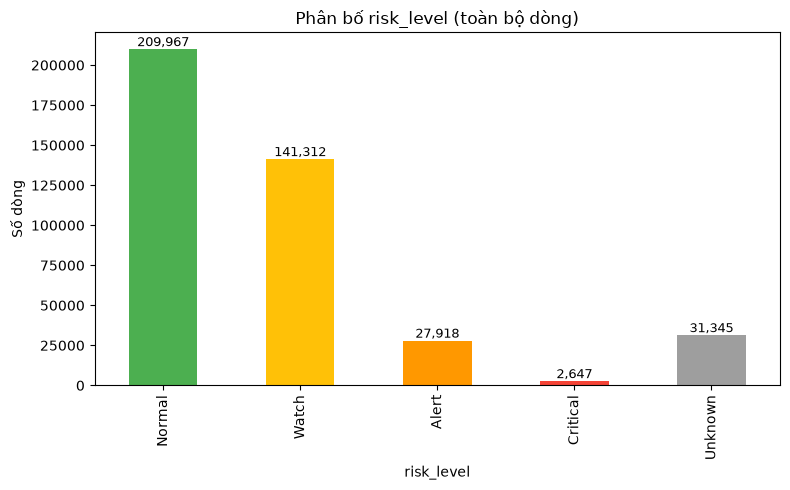

In [31]:
import matplotlib.pyplot as plt

order = ["Normal", "Watch", "Alert", "Critical", "Unknown"]
counts = label_df["risk_level"].value_counts().reindex(order).fillna(0)

fig, ax = plt.subplots(figsize=(8, 5))
counts.plot(kind="bar", ax=ax, color=["#4CAF50", "#FFC107", "#FF9800", "#F44336", "#9E9E9E"])
ax.set_title("Phân bố risk_level (toàn bộ dòng)")
ax.set_ylabel("Số dòng")
for i, v in enumerate(counts):
    ax.text(i, v, f"{int(v):,}", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

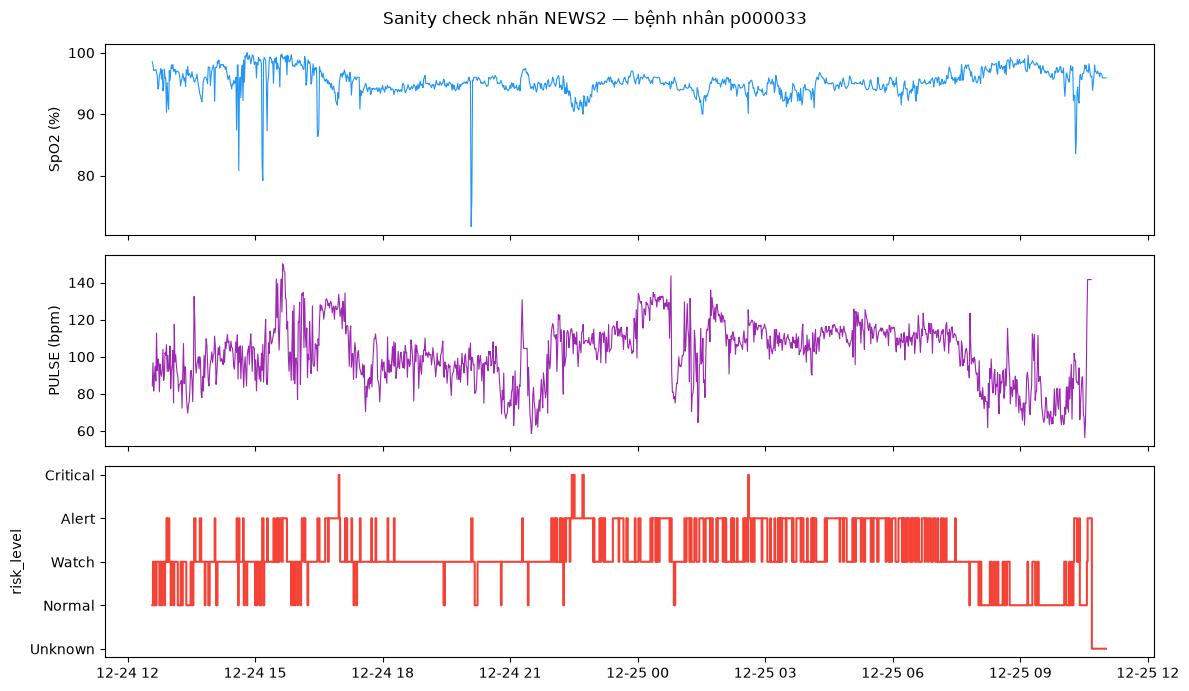

In [32]:
sample_patient = (
    label_df[label_df["risk_level"] != "Unknown"]
    .groupby("patient_id")["risk_level"].nunique()
    .sort_values(ascending=False)
    .index[0]
)
sample_df = label_df[label_df["patient_id"] == sample_patient].sort_values("timestamp")

fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)

axes[0].plot(sample_df["timestamp"], sample_df["SPO2"], color="#2196F3", linewidth=0.8)
axes[0].set_ylabel("SpO2 (%)")

axes[1].plot(sample_df["timestamp"], sample_df["PULSE"], color="#9C27B0", linewidth=0.8)
axes[1].set_ylabel("PULSE (bpm)")

risk_map = {"Normal": 0, "Watch": 1, "Alert": 2, "Critical": 3, "Unknown": -1}
axes[2].step(sample_df["timestamp"], sample_df["risk_level"].map(risk_map), where="post", color="#F44336")
axes[2].set_yticks(list(risk_map.values()))
axes[2].set_yticklabels(list(risk_map.keys()))
axes[2].set_ylabel("risk_level")

fig.suptitle(f"Sanity check nhãn NEWS2 — bệnh nhân {sample_patient}")
plt.tight_layout()
plt.show()